In [2]:
from pathlib import Path
import pydicom
import pandas as pd
import numpy as np
from idc_index import index

# Project root = the folder that contains data/ (this notebook lives one level down, in final_project/)
ROOT = Path.cwd().resolve().parent
DATA_DIR = ROOT / "data"
ANNOTATIONS_DIR = DATA_DIR / "annotations" / "bonemarrowwsi_pediatricleukemia"
CELL_CROPS_DIR = DATA_DIR / "crops"
WSI_DIR = DATA_DIR / "wsi"
assert ANNOTATIONS_DIR.exists(), f"annotations not found at {ANNOTATIONS_DIR}"

annotation_files = sorted(ANNOTATIONS_DIR.rglob("*.dcm"))

print("Number of annotation files:" + str(len(annotation_files)))

NameError: name 'annotation_dir' is not defined

In [ ]:
#load all annotation failes into loaded
loaded = []
failed = []

for file in annotation_files:
    try:
        ds = pydicom.dcmread(file)
        loaded.append(ds)
    except Exception as e:
        failed.append((file, e))

print("loaded: " + str(len(loaded)))
print("failed: " + str(len(failed)))

loaded: 113
failed: 0


In [45]:
#print metadata regarding one patient
ds = loaded[0]

print("Patient ID:", ds.PatientID)
print("Modality:", ds.Modality)
print("Series Description:", ds.SeriesDescription)
print("Diagnosis:", getattr(ds, "AdmittingDiagnosesDescription", "MISSING"))
print("Annotation groups:", len(ds.AnnotationGroupSequence))

Patient ID: 02522A2B2726FB0A03BB19F2D8D9524D
Modality: ANN
Series Description: Consensus: cell bounding boxes with cell type labels
Diagnosis: Acute Monocytic Leukemia
Annotation groups: 16


In [ ]:
#in this one one patient annotation, how many cells exist and what types are they?
for group in ds.AnnotationGroupSequence:
    print(
        group.AnnotationGroupLabel,
        "->",
        group.NumberOfAnnotations
    )

artifact -> 4
damaged_cell -> 22
eosinophilic_myelocyte -> 1
giant_platelet -> 2
lymphocytic_blast -> 5
monocytic_blast -> 6
myelocytic_blast -> 73
neutrophil_extracellular_trap -> 2
neutrophilic_band -> 2
orthochromatic_erythroblast -> 1
phagocytosis -> 1
promyelocyte -> 3
segmented_neutrophil -> 1
smudge_cell -> 14
technically_unfit -> 49
unknown_blast -> 10


In [51]:
group = ds.AnnotationGroupSequence[2]

coords = np.frombuffer(
    group.PointCoordinatesData,
    dtype="<f4"
).reshape(int(group.NumberOfAnnotations), 4, 2)

print("Label:", group.AnnotationGroupLabel)
print("Shape:", coords.shape)
print("First rectangle:")
print(coords)

Label: eosinophilic_myelocyte
Shape: (1, 4, 2)
First rectangle:
[[[ 92443. 190134.]
  [ 92578. 190134.]
  [ 92578. 190264.]
  [ 92443. 190264.]]]


In [16]:
cml_chronic = []

for ds in loaded:
    diagnosis = str(getattr(ds, "AdmittingDiagnosesDescription", ""))

    if "Chronic Phase Chronic Myeloid Leukemia" in diagnosis:
        cml_chronic.append(ds)

print("Chronic-phase CML patients:", len(cml_chronic))

Chronic-phase CML patients: 46


In [17]:
target_labels = [
    "promyelocyte",
    "neutrophilic_myelocyte",
    "neutrophilic_metamyelocyte",
    "neutrophilic_band",
    "segmented_neutrophil",
]

stage_counts = {label: 0 for label in target_labels}
stage_patients = {label: 0 for label in target_labels}

for ds in cml_chronic:
    patient_labels = {
        str(group.AnnotationGroupLabel): int(group.NumberOfAnnotations)
        for group in ds.AnnotationGroupSequence
    }

    for label in target_labels:
        n = patient_labels.get(label, 0)
        stage_counts[label] += n

        if n > 0:
            stage_patients[label] += 1

for label in target_labels:
    print(
        f"{label:30s} "
        f"{stage_counts[label]:5d} cells | "
        f"{stage_patients[label]:2d} patients"
    )

print("\nTotal cells:", sum(stage_counts.values()))

promyelocyte                    1510 cells | 45 patients
neutrophilic_myelocyte          1460 cells | 46 patients
neutrophilic_metamyelocyte       926 cells | 46 patients
neutrophilic_band               1771 cells | 46 patients
segmented_neutrophil            2673 cells | 46 patients

Total cells: 8340


In [18]:
ds = cml_chronic[0]

print("Patient ID:", ds.PatientID)
print("Study UID:", ds.StudyInstanceUID)
print("Annotation Series UID:", ds.SeriesInstanceUID)

print("\nReference-related elements:")
for elem in ds.iterall():
    if "Referenced" in elem.name:
        print(elem)

Patient ID: 02E74F10E0327AD868D138F2B4FDD6F0
Study UID: 1.2.826.0.1.3680043.8.498.43052523198542423692726125062103241255
Annotation Series UID: 1.2.826.0.1.3680043.10.511.3.65340408039479593258834224891073999

Reference-related elements:
(0008,1115) Referenced Series Sequence          SQ: <Sequence, length 1>
(0008,114A) Referenced Instance Sequence        SQ: <Sequence, length 1>
(0008,1150) Referenced SOP Class UID            UI: VL Whole Slide Microscopy Image Storage
(0008,1155) Referenced SOP Instance UID         UI: 1.2.826.0.1.3680043.8.498.93422388789094217588665950184663030754
(0008,1140) Referenced Image Sequence           SQ: <Sequence, length 1>
(0008,1150) Referenced SOP Class UID            UI: VL Whole Slide Microscopy Image Storage
(0008,1155) Referenced SOP Instance UID         UI: 1.2.826.0.1.3680043.8.498.93422388789094217588665950184663030754


In [19]:
series_uid = str(
    ds.ReferencedSeriesSequence[0].SeriesInstanceUID
)

result = client.sql_query(f"""
SELECT *
FROM index
WHERE SeriesInstanceUID = '{series_uid}'
""")

print(result.T)

NameError: name 'client' is not defined

In [10]:
help(client.download_dicom_instance)

NameError: name 'client' is not defined

In [41]:
referenced_sop_uid = str(
    ds.ReferencedSeriesSequence[0]
      .ReferencedInstanceSequence[0]
      .ReferencedSOPInstanceUID
)

print("Referenced SOP Instance UID:")
print(referenced_sop_uid)

client.download_dicom_instance(
    sopInstanceUID=referenced_sop_uid,
    downloadDir=str(WSI_DIR),
    dry_run=True,
    quiet=False
)

2026-09-29 11:15:00,208 - Instance-level access not possible because instance-level index not installed.


Referenced SOP Instance UID:
1.2.826.0.1.3680043.8.498.93422388789094217588665950184663030754


ValueError: Instance-level access not possible because instance-level index not installed.

In [43]:
client.fetch_index("sm_instance_index")

2026-09-29 11:16:03,618 - Fetching index sm_instance_index


In [44]:
print(type(client.sm_instance_index))
print(client.sm_instance_index.shape)
print(client.sm_instance_index.columns.tolist())

<class 'pandas.DataFrame'>
(391932, 15)
['SOPInstanceUID', 'SeriesInstanceUID', 'embeddingMedium_CodeMeaning', 'embeddingMedium_code_designator_value_str', 'tissueFixative_CodeMeaning', 'tissueFixative_code_designator_value_str', 'staining_usingSubstance_CodeMeaning', 'staining_usingSubstance_code_designator_value_str', 'PixelSpacing_0', 'ImageType', 'TransferSyntaxUID', 'instance_size', 'TotalPixelMatrixColumns', 'TotalPixelMatrixRows', 'crdc_instance_uuid']


In [45]:
series_instances = client.sm_instance_index[
    client.sm_instance_index["SeriesInstanceUID"] == series_uid
].copy()

series_instances[
    [
        "SOPInstanceUID",
        "ImageType",
        "TotalPixelMatrixColumns",
        "TotalPixelMatrixRows",
        "instance_size",
    ]
]

,SOPInstanceUID,ImageType,TotalPixelMatrixColumns,TotalPixelMatrixRows,instance_size
390536,1.2.826.0.1.3680043.8.498.43042424132033529899...,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",46528,111872,824637988
390537,1.2.826.0.1.3680043.8.498.37890446828667261538...,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",2908,6992,5108480
390538,1.2.826.0.1.3680043.8.498.83377147053572774758...,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",11632,27968,75297498
390539,1.2.826.0.1.3680043.8.498.93422388789094217588...,"[ORIGINAL, PRIMARY, VOLUME, NONE]",186112,447488,9833878506
390540,1.2.826.0.1.3680043.8.498.22822417944934296878...,"[ORIGINAL, PRIMARY, OVERVIEW, NONE]",535,1083,106910
390541,1.2.826.0.1.3680043.8.498.41109233356688786415...,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",727,1748,324686


In [46]:
series_instances["referenced_by_annotation"] = (
    series_instances["SOPInstanceUID"] == referenced_sop_uid
)

series_instances[
    [
        "SOPInstanceUID",
        "ImageType",
        "TotalPixelMatrixColumns",
        "TotalPixelMatrixRows",
        "instance_size",
        "referenced_by_annotation",
    ]
]

,SOPInstanceUID,ImageType,TotalPixelMatrixColumns,TotalPixelMatrixRows,instance_size,referenced_by_annotation
390536,1.2.826.0.1.3680043.8.498.43042424132033529899...,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",46528,111872,824637988,False
390537,1.2.826.0.1.3680043.8.498.37890446828667261538...,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",2908,6992,5108480,False
390538,1.2.826.0.1.3680043.8.498.83377147053572774758...,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",11632,27968,75297498,False
390539,1.2.826.0.1.3680043.8.498.93422388789094217588...,"[ORIGINAL, PRIMARY, VOLUME, NONE]",186112,447488,9833878506,True
390540,1.2.826.0.1.3680043.8.498.22822417944934296878...,"[ORIGINAL, PRIMARY, OVERVIEW, NONE]",535,1083,106910,False
390541,1.2.826.0.1.3680043.8.498.41109233356688786415...,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",727,1748,324686,False


In [47]:
series_instances[
    [
        "ImageType",
        "TotalPixelMatrixColumns",
        "TotalPixelMatrixRows",
        "PixelSpacing_0",
        "instance_size",
        "referenced_by_annotation",
    ]
]

,ImageType,TotalPixelMatrixColumns,TotalPixelMatrixRows,PixelSpacing_0,instance_size,referenced_by_annotation
390536,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",46528,111872,0.000443,824637988,False
390537,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",2908,6992,0.007086,5108480,False
390538,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",11632,27968,0.001772,75297498,False
390539,"[ORIGINAL, PRIMARY, VOLUME, NONE]",186112,447488,0.000111,9833878506,True
390540,"[ORIGINAL, PRIMARY, OVERVIEW, NONE]",535,1083,NaN,106910,False
390541,"[DERIVED, PRIMARY, VOLUME, RESAMPLED]",727,1748,0.028345,324686,False


In [48]:
four_x = series_instances[
    series_instances["PixelSpacing_0"].between(0.00044, 0.00045)
].iloc[0]

four_x_sop_uid = four_x["SOPInstanceUID"]

print(four_x_sop_uid)
print(f"{four_x['instance_size'] / 1e6:.1f} MB")

1.2.826.0.1.3680043.8.498.43042424132033529899079549987168688929
824.6 MB


In [ ]:
# client.download_dicom_instance(
#     sopInstanceUID=four_x_sop_uid,
#     downloadDir=str(WSI_DIR),
#     quiet=False
# )

2026-09-29 11:51:06,792 - Disk size needed: 824.64 MB
2026-09-29 11:51:06,793 - Disk size available: 35.15 GB
2026-09-29 11:51:10,292 - Not using s5cmd sync as the destination folder is empty or sync or progress bar is not requested
2026-09-29 11:51:10,330 - Initial size of the directory: 0 bytes
2026-09-29 11:51:10,332 - Approximate size of the files that need to be downloaded: 824.64 MB

cp s3://idc-open-data/3c8fb90f-e3f9-4d9d-bac8-db2ae1e7b038/16c1fa55-e554-4567-aea5-726cdb636050.dcm /Users/abishekchozhan/Documents/peds_heme_onc/peds-leukemia/notebooks/data/wsi/bonemarrowwsi_pediatricleukemia/02E74F10E0327AD868D138F2B4FDD6F0/1.2.826.0.1.3680043.8.498.43052523198542423692726125062103241255/SM_1.2.826.0.1.3680043.8.498.80094077060073240269692861378417112485


2026-09-29 11:51:39,251 - Successfully downloaded files to /Users/abishekchozhan/Documents/peds_heme_onc/peds-leukemia/notebooks/data/wsi


In [21]:
from pathlib import Path

wsi_files = list(WSI_DIR.rglob("*.dcm"))

print("Files:", len(wsi_files))
print(wsi_files[0])

Files: 1
data/wsi/bonemarrowwsi_pediatricleukemia/02E74F10E0327AD868D138F2B4FDD6F0/1.2.826.0.1.3680043.8.498.43052523198542423692726125062103241255/SM_1.2.826.0.1.3680043.8.498.80094077060073240269692861378417112485.dcm


In [22]:
wsi = pydicom.dcmread(
    wsi_files[0],
    stop_before_pixels=True
)

print("SOP Instance UID:", wsi.SOPInstanceUID)
print("Image Type:", wsi.ImageType)
print("Total matrix:", wsi.TotalPixelMatrixColumns, "x", wsi.TotalPixelMatrixRows)
print("Tile size:", wsi.Columns, "x", wsi.Rows)
print("Number of frames:", wsi.NumberOfFrames)

SOP Instance UID: 1.2.826.0.1.3680043.8.498.43042424132033529899079549987168688929
Image Type: ['DERIVED', 'PRIMARY', 'VOLUME', 'RESAMPLED']
Total matrix: 46528 x 111872
Tile size: 1024 x 1024
Number of frames: 5060


In [23]:
from wsidicom import WsiDicom

slide = WsiDicom.open(wsi_files[0])

print(slide)

WsiDicom of pyramids:
[0]: Pyramid of levels:
      [0]: Level: 0, size: Size(width=46528, height=111872) px, mpp: SizeMm(width=0.44217821782, height=0.44289473683999997) um/px Instances:         [0]: default z: 0.0 default path: 0 ImageData WsiDicomFileImageData of files [<wsidicom.file.io.wsidicom_reader.WsiDicomReader object at 0x13a3d8510>]


In [24]:
for level in slide.levels:
    print(
        "Level:", level.level,
        "| Size:", level.size,
        "| Pixel spacing:", level.pixel_spacing
    )

Level: 0 | Size: Size(width=46528, height=111872) | Pixel spacing: SizeMm(width='0.00044217821782', height='0.00044289473684')


In [25]:
promyelo_group = next(
    group for group in ds.AnnotationGroupSequence
    if group.AnnotationGroupLabel == "promyelocyte"
)

coords_full = np.frombuffer(
    promyelo_group.PointCoordinatesData,
    dtype="<f4"
).reshape(int(promyelo_group.NumberOfAnnotations), 4, 2)

bbox = coords_full[0]

x_min = bbox[:, 0].min()
x_max = bbox[:, 0].max()
y_min = bbox[:, 1].min()
y_max = bbox[:, 1].max()

print("Full-resolution bbox:")
print(x_min, y_min, x_max, y_max)

Full-resolution bbox:
64703.0 168173.0 64902.0 168361.0


In [28]:
x_scale = 46528 / 186112
y_scale = 111872 / 447488

print("x scale:", x_scale)
print("y scale:", y_scale)

x_min_4x = round(x_min * x_scale)
x_max_4x = round(x_max * x_scale)

y_min_4x = round(y_min * y_scale)
y_max_4x = round(y_max * y_scale)

print("Full-resolution bbox:")
print(x_min, y_min, x_max, y_max)

print("\n4× bbox:")
print(x_min_4x, y_min_4x, x_max_4x, y_max_4x)

print("\n4× size:")
print(x_max_4x - x_min_4x, "×", y_max_4x - y_min_4x)

x scale: 0.25
y scale: 0.25
Full-resolution bbox:
64703.0 168173.0 64902.0 168361.0

4× bbox:
16176 42043 16226 42090

4× size:
50 × 47


In [30]:
center_x = round((x_min_4x + x_max_4x) / 2)
center_y = round((y_min_4x + y_max_4x) / 2)

crop_size = 200

location = (
    center_x - crop_size // 2,
    center_y - crop_size // 2
)

region = slide.read_region(
    location=location,
    level=0,
    size=(crop_size, crop_size)
)

print(region.size)

(200, 200)


Matplotlib is building the font cache; this may take a moment.


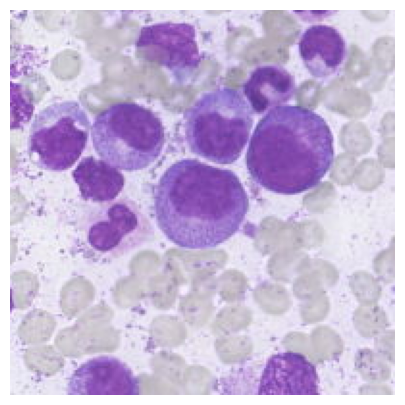

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.imshow(region)
plt.axis("off")
plt.show()

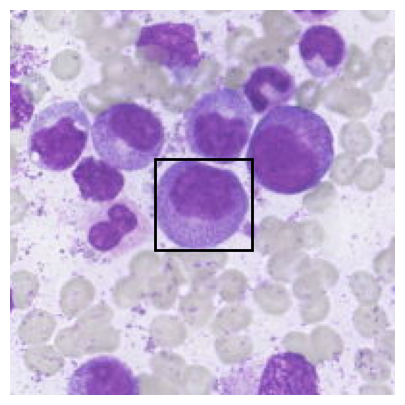

In [32]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(region)

# Bounding box coordinates relative to our 200x200 crop
rect_x = x_min_4x - location[0]
rect_y = y_min_4x - location[1]
rect_w = x_max_4x - x_min_4x
rect_h = y_max_4x - y_min_4x

rect = patches.Rectangle(
    (rect_x, rect_y),
    rect_w,
    rect_h,
    fill=False,
    linewidth=2
)

ax.add_patch(rect)
ax.axis("off")
plt.show()

In [33]:
import numpy as np
import pandas as pd

target_stages = [
    "promyelocyte",
    "neutrophilic_myelocyte",
    "neutrophilic_metamyelocyte",
    "neutrophilic_band",
    "segmented_neutrophil",
]

rows = []

for ds in cml_chronic:
    patient_id = str(ds.PatientID)

    for group in ds.AnnotationGroupSequence:
        label = str(group.AnnotationGroupLabel)

        if label not in target_stages:
            continue

        n = int(group.NumberOfAnnotations)

        coords = np.frombuffer(
            group.PointCoordinatesData,
            dtype="<f4"
        ).reshape(n, 4, 2)

        for bbox in coords:
            x_min = bbox[:, 0].min()
            x_max = bbox[:, 0].max()
            y_min = bbox[:, 1].min()
            y_max = bbox[:, 1].max()

            rows.append({
                "patient_id": patient_id,
                "stage": label,
                "x_min": x_min,
                "y_min": y_min,
                "x_max": x_max,
                "y_max": y_max,
                "width": x_max - x_min,
                "height": y_max - y_min,
            })

bbox_df = pd.DataFrame(rows)

print("Cells:", len(bbox_df))
bbox_df.head()

Cells: 8340


,patient_id,stage,x_min,y_min,x_max,y_max,width,height
0,02E74F10E0327AD868D138F2B4FDD6F0,neutrophilic_band,64887.0,167977.0,64999.0,168085.0,112.0,108.0
1,02E74F10E0327AD868D138F2B4FDD6F0,neutrophilic_band,63832.0,168301.0,63968.0,168456.0,136.0,155.0
2,02E74F10E0327AD868D138F2B4FDD6F0,neutrophilic_band,63177.0,167705.0,63274.0,167804.0,97.0,99.0
3,02E74F10E0327AD868D138F2B4FDD6F0,neutrophilic_band,63527.0,167372.0,63627.0,167491.0,100.0,119.0
4,02E74F10E0327AD868D138F2B4FDD6F0,neutrophilic_band,63062.0,167629.0,63176.0,167741.0,114.0,112.0


In [35]:
print(
    bbox_df[["width", "height"]]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
)

print("\nPercentage fitting entirely within 224 × 224:")
print(
    ((bbox_df["width"] <= 224) & (bbox_df["height"] <= 224)).mean() * 100
)
print(((bbox_df["width"] <= 224) & (bbox_df["height"] <= 224)).mean() * 100 * 8340)

             width       height
count  8340.000000  8340.000000
mean    127.693047   129.347244
std      28.937574    29.052679
min      39.000000    43.000000
1%       60.000000    62.000000
5%       73.000000    74.000000
25%     112.000000   114.000000
50%     128.000000   129.500000
75%     146.000000   147.000000
95%     175.000000   177.000000
99%     197.000000   202.000000
max     243.000000   286.000000

Percentage fitting entirely within 224 × 224:
99.77218225419664
832100.0


In [36]:
oversized = bbox_df[
    (bbox_df["width"] > 224) |
    (bbox_df["height"] > 224)
].copy()

print("Oversized cells:", len(oversized))

print(
    oversized[
        ["patient_id", "stage", "width", "height"]
    ].sort_values(["width", "height"], ascending=False)
)

Oversized cells: 19
                            patient_id                       stage  width  \
7874  E4DA3B7FBBCE2345D7772B0674A318D5  neutrophilic_metamyelocyte  243.0   
89    02E74F10E0327AD868D138F2B4FDD6F0                promyelocyte  241.0   
1898  3C59DC048E8850243BE8079A5C74D079  neutrophilic_metamyelocyte  238.0   
5466  AAB3238922BCC25A6F606EB525FFDC56                promyelocyte  235.0   
1504  3416A75F4CEA9109507CACD8E2F2AEFC                promyelocyte  235.0   
1111  1F0E3DAD99908345F7439F8FFABDFFC4  neutrophilic_metamyelocyte  235.0   
1910  3C59DC048E8850243BE8079A5C74D079      neutrophilic_myelocyte  233.0   
6176  C20AD4D76FE97759AA27A0C99BFF6710                promyelocyte  232.0   
6856  C9F0F895FB98AB9159F51FD0297E236D                promyelocyte  232.0   
1917  3C59DC048E8850243BE8079A5C74D079                promyelocyte  227.0   
3341  70EFDF2EC9B086079795C442636B55FB      neutrophilic_myelocyte  226.0   
1496  3416A75F4CEA9109507CACD8E2F2AEFC                pr

In [ ]:
bbox_df["max_dimension"] = bbox_df[["width", "height"]].max(axis=1)

bbox_df["max_dimension"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]
)

count    8340.000000
mean      135.775772
std        29.420156
min        50.000000
25%       121.000000
50%       136.000000
75%       153.000000
90%       172.000000
95%       184.000000
99%       208.000000
max       286.000000
Name: max_dimension, dtype: float64

In [55]:
client = index.IDCClient()
client.fetch_index("sm_instance_index")

client.download_dicom_instance(
    sopInstanceUID=referenced_sop_uid,
    downloadDir=str(WSI_DIR),
    quiet=False
)

2026-09-29 14:12:25,493 - Index sm_instance_index already installed, loading from /Users/abishekchozhan/Library/Application Support/idc_index_data/24.2.2/sm_instance_index.parquet


NameError: name 'referenced_sop_uid' is not defined